# 11 - Segmentación de perfiles de servicios y transporte

- Unidad: barrio (48 observaciones).
- K-means y agrupamiento jerárquico se comparan sobre componentes principales retenidos.
- Se evalúan silueta, estabilidad ante submuestras e interpretación sustantiva.
- La segmentación es exploratoria; no define categorías oficiales ni prioriza por sí sola una política.
- Insumos: coordenadas PCA de 10 y KPIs por barrio de 07.
- Salidas: etiquetas y perfiles en `data/processed/` y `data/processed/reports/`.

## 1. Preparación y selección de dimensiones

- Se retienen los componentes que explican al menos 80% de la varianza, con máximo de cinco.
- La regla mantiene parsimonia con 48 barrios.
- Se comprueba que haya casos suficientes para evaluar los valores candidatos de k.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from src import config

REPORTS = config.REPORTS_DIR
scores = pd.read_csv(config.PROCESSED_DIR / "pe3_pca_barrios_scores_v1.csv")
varianza = pd.read_csv(REPORTS / "pe3_pca_varianza_v1.csv")
kb = pd.read_csv(config.PROCESSED_DIR / "kpis_barrio_v1.csv")

pc_cols = [c for c in scores.columns if c.startswith("PC") and c[2:].isdigit()]
pc_cols = sorted(pc_cols, key=lambda c: int(c[2:]))
n_pc_80 = int(np.searchsorted(varianza["varianza_explicada"].cumsum().to_numpy(), .80) + 1)
n_pc = min(max(n_pc_80, 2), 5, len(pc_cols))
X = scores[pc_cols[:n_pc]].to_numpy()
barrios = scores["barrio_oficial"].astype(str)
print("Componentes usados:", pc_cols[:n_pc])
print("Varianza acumulada:", round(varianza["varianza_explicada"].iloc[:n_pc].sum(), 3))

Componentes usados: ['PC1', 'PC2', 'PC3', 'PC4', 'PC5']
Varianza acumulada: 0.867


## 2. Comparación de soluciones

- Se comparan k entre 2 y 5.
- La silueta evalúa separación geométrica, no validez social o habitacional.
- La estabilidad se estima con submuestras aleatorias; ARI compara asignaciones de los barrios compartidos.
- Se informa un candidato mecánico y se revisa su interpretación antes de elegir la solución final.

In [2]:
rng = np.random.default_rng(2026)
resultados = []
modelos = {}
n = len(X)
for k in range(2, min(5, n - 1) + 1):
    km = KMeans(n_clusters=k, n_init=50, random_state=2026).fit(X)
    modelos[k] = km
    sil_km = silhouette_score(X, km.labels_)
    ward = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X)
    sil_ward = silhouette_score(X, ward.labels_)

    soluciones = []
    for rep in range(30):
        idx = np.sort(rng.choice(n, size=max(k + 2, int(.8 * n)), replace=False))
        labels = KMeans(n_clusters=k, n_init=20, random_state=rep).fit_predict(X[idx])
        soluciones.append((idx, labels))
    ari = []
    for i in range(len(soluciones)):
        idx_i, lab_i = soluciones[i]
        map_i = dict(zip(idx_i, lab_i))
        for j in range(i + 1, len(soluciones)):
            idx_j, lab_j = soluciones[j]
            comunes = np.intersect1d(idx_i, idx_j)
            if len(comunes) > k:
                ari.append(adjusted_rand_score(
                    [map_i[q] for q in comunes],
                    [dict(zip(idx_j, lab_j))[q] for q in comunes]
                ))
    resultados.append({
        "k": k, "silueta_kmeans": sil_km, "silueta_ward": sil_ward,
        "ari_mediana_submuestras": float(np.median(ari)) if ari else np.nan
    })

validacion = pd.DataFrame(resultados).sort_values("k")
display(validacion.round(3))
k_candidato = int(validacion.loc[validacion["silueta_kmeans"].idxmax(), "k"])
print("Candidato por silueta K-means (requiere revisión interpretativa):", k_candidato)
validacion.to_csv(REPORTS / "pe3_validacion_clustering_v1.csv", index=False)

,k,silueta_kmeans,silueta_ward,ari_mediana_submuestras
0,2,0.275,0.266,0.718
1,3,0.328,0.279,0.515
2,4,0.232,0.263,0.517
3,5,0.249,0.257,0.506


Candidato por silueta K-means (requiere revisión interpretativa): 3


## 3. Perfiles y lectura territorial

- Se describe cada grupo con medianas y rangos de los KPIs originales.
- Se muestra la distribución en PC1-PC2; cada punto representa un barrio.
- Los rótulos comunales ayudan a relacionar perfiles con los patrones de 08, sin reemplazar el diagnóstico.

,barrios,airbnb_por_km2,mediana_precio_m2_venta_usd,mediana_precio_m2_alquiler_usd,densidad_culturales_km2,densidad_subte_km2,densidad_educacion_km2,pct_superficie_verde
cluster,,,,,,,,
1,10,145.63,2419.99,14.50,42.30,0.99,9.80,2.40
2,37,5.12,2348.48,12.28,5.06,0.00,7.09,1.11
3,1,36.88,6387.35,27.40,3.77,0.00,0.40,52.41


,barrio_oficial,cluster
2,Balvanera,1
4,Belgrano,1
10,Colegiales,1
11,Constitucion,1
16,Monserrat,1
20,Palermo,1
27,Recoleta,1
28,Retiro,1
31,San Nicolas,1
32,San Telmo,1


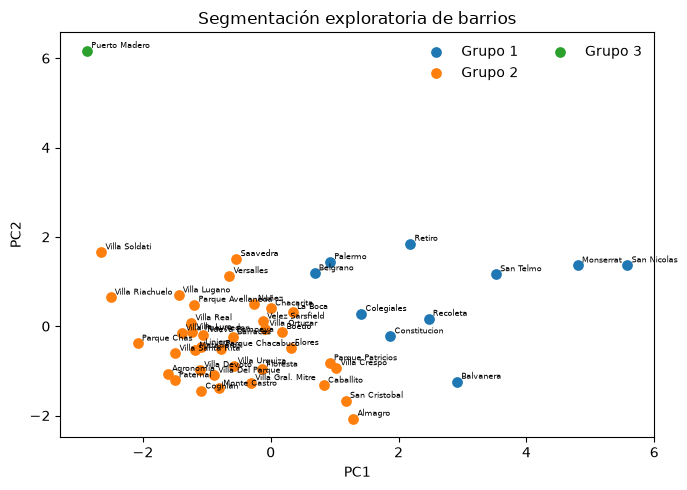

In [3]:
labels = modelos[k_candidato].labels_
asignacion = pd.DataFrame({"barrio_oficial": barrios, "cluster": labels + 1})
perfil = asignacion.merge(kb, on="barrio_oficial", validate="one_to_one")
columnas_perfil = [
    "airbnb_por_km2", "mediana_precio_m2_venta_usd",
    "mediana_precio_m2_alquiler_usd", "densidad_culturales_km2",
    "densidad_subte_km2", "densidad_educacion_km2", "pct_superficie_verde"
]
columnas_perfil = [c for c in columnas_perfil if c in perfil.columns]
resumen = perfil.groupby("cluster")[columnas_perfil].median().round(2)
resumen.insert(0, "barrios", perfil.groupby("cluster").size())
display(resumen)
display(asignacion.sort_values(["cluster", "barrio_oficial"]))
asignacion.to_csv(config.PROCESSED_DIR / "pe3_clusters_barrios_v1.csv", index=False)
resumen.to_csv(REPORTS / "pe3_perfiles_clusters_v1.csv")

fig, ax = plt.subplots(figsize=(7, 5))
for cluster, grupo in asignacion.groupby("cluster"):
    ix = grupo.index
    ax.scatter(scores.loc[ix, "PC1"], scores.loc[ix, "PC2"], s=45, label="Grupo " + str(cluster))
    for i in ix:
        ax.annotate(barrios.iloc[i], (scores.loc[i, "PC1"], scores.loc[i, "PC2"]),
                    xytext=(3, 2), textcoords="offset points", fontsize=6)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Segmentación exploratoria de barrios")
ax.legend(frameon=False, ncol=2)
plt.tight_layout()
plt.show()

**Interpretación provisional.** La lectura cuantitativa se genera desde las tablas ejecutadas al cierre de este notebook. El notebook 16 contrasta estabilidad, supuestos y sensibilidad. Los resultados describen oferta publicada y asociaciones; la redacción final se acordará al cerrar la entrega.

In [4]:
# Comparación de los KPIs originales entre clusters territoriales
# Prueba global no paramétrica + tamaño de efecto

from scipy.stats import kruskal

variables_comparar = [
    "airbnb_por_km2",
    "mediana_precio_m2_venta_usd",
    "mediana_precio_m2_alquiler_usd",
    "densidad_culturales_km2",
    "densidad_subte_km2",
    "densidad_educacion_km2",
    "pct_superficie_verde"
]

variables_comparar = [
    v for v in variables_comparar
    if v in perfil.columns
]

resultados_clusters = []

for variable in variables_comparar:
    grupos = [
        grupo[variable].dropna().to_numpy()
        for _, grupo in perfil.groupby("cluster")
    ]

    grupos = [g for g in grupos if len(g) > 0]

    if len(grupos) < 2 or min(map(len, grupos)) < 5:
        resultados_clusters.append({"variable": variable, "n": sum(map(len, grupos)),
            "estadistico_kruskal": np.nan, "p_valor": np.nan, "eta2_aproximado": np.nan,
            "estado": "No estimable: al menos un grupo con menos de 5 barrios"})
        continue

    if any(len(np.unique(g)) < 2 for g in grupos):
        # Si todos los valores de algún grupo son iguales,
        # Kruskal puede no ser calculable de forma informativa.
        if all(np.ptp(g) == 0 for g in grupos):
            continue

    try:
        estadistico, p_valor = kruskal(*grupos)
    except ValueError:
        continue

    n_total = sum(len(g) for g in grupos)
    k_grupos = len(grupos)

    # Eta cuadrado de Kruskal-Wallis: medida aproximada
    # de magnitud, que complementa al p-valor.
    eta2 = max(
        0,
        (estadistico - k_grupos + 1) / (n_total - k_grupos)
    ) if n_total > k_grupos else np.nan

    resultados_clusters.append({
        "variable": variable,
        "n": n_total,
        "estadistico_kruskal": estadistico,
        "p_valor": p_valor,
        "eta2_aproximado": eta2
    })

comparacion_clusters = pd.DataFrame(resultados_clusters)

# Corrección de Benjamini-Hochberg por pruebas múltiples
if not comparacion_clusters.empty:
    p = comparacion_clusters["p_valor"].to_numpy()
    orden = np.argsort(p)
    m = len(p)
    p_ordenados = p[orden]

    ajustados_ordenados = np.minimum.accumulate(
        (p_ordenados * m / np.arange(1, m + 1))[::-1]
    )[::-1]

    p_ajustados = np.empty(m)
    p_ajustados[orden] = np.minimum(ajustados_ordenados, 1)

    comparacion_clusters["p_ajustado_BH"] = p_ajustados

    display(
        comparacion_clusters.sort_values("p_ajustado_BH").round(4)
    )

    comparacion_clusters.to_csv(
        REPORTS / "pe3_diferencias_kpis_entre_clusters_v1.csv",
        index=False
    )
if comparacion_clusters.empty:
    print("No se emiten p-valores de Kruskal: algún grupo tiene menos de 5 barrios. Usar perfiles descriptivos y validación externa en 16.")


,variable,n,estadistico_kruskal,p_valor,eta2_aproximado,estado,p_ajustado_BH
0,airbnb_por_km2,48,NaN,NaN,NaN,No estimable: al menos un grupo con menos de 5...,NaN
1,mediana_precio_m2_venta_usd,48,NaN,NaN,NaN,No estimable: al menos un grupo con menos de 5...,NaN
2,mediana_precio_m2_alquiler_usd,41,NaN,NaN,NaN,No estimable: al menos un grupo con menos de 5...,NaN
3,densidad_culturales_km2,48,NaN,NaN,NaN,No estimable: al menos un grupo con menos de 5...,NaN
4,densidad_subte_km2,48,NaN,NaN,NaN,No estimable: al menos un grupo con menos de 5...,NaN
5,densidad_educacion_km2,48,NaN,NaN,NaN,No estimable: al menos un grupo con menos de 5...,NaN
6,pct_superficie_verde,48,NaN,NaN,NaN,No estimable: al menos un grupo con menos de 5...,NaN


**Interpretación provisional.** La lectura cuantitativa se genera desde las tablas ejecutadas al cierre de este notebook. El notebook 16 contrasta estabilidad, supuestos y sensibilidad. Los resultados describen oferta publicada y asociaciones; la redacción final se acordará al cerrar la entrega.

## 4. Decisión metodológica provisional

- Elegir k requiere considerar silueta, estabilidad y si los perfiles tienen sentido para el Instituto.
- Si una solución es inestable o los grupos solo reflejan densidad de publicaciones, no se conserva como segmentación final.
- Los resultados sirven para organizar el análisis posterior; no son una clasificación del déficit habitacional.
- Revisar sensibilidad a variables, número de componentes, método jerárquico y exclusión de barrios con poca cobertura.

## Panel visual de síntesis: calidad geométrica y perfiles
Las métricas de validación no eligen por sí solas una segmentación. El primer panel permite comparar silueta y estabilidad para cada valor de *k*. El mapa de calor reescala cada KPI entre sus propios grupos para mostrar el perfil relativo; los colores no permiten comparar magnitudes entre KPIs con unidades distintas.

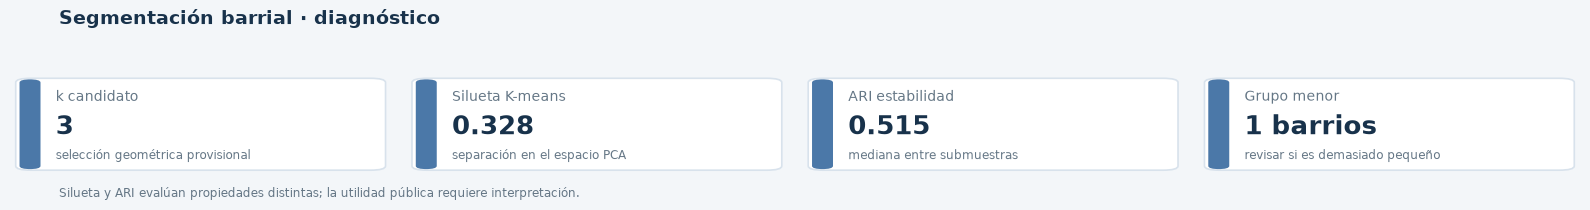

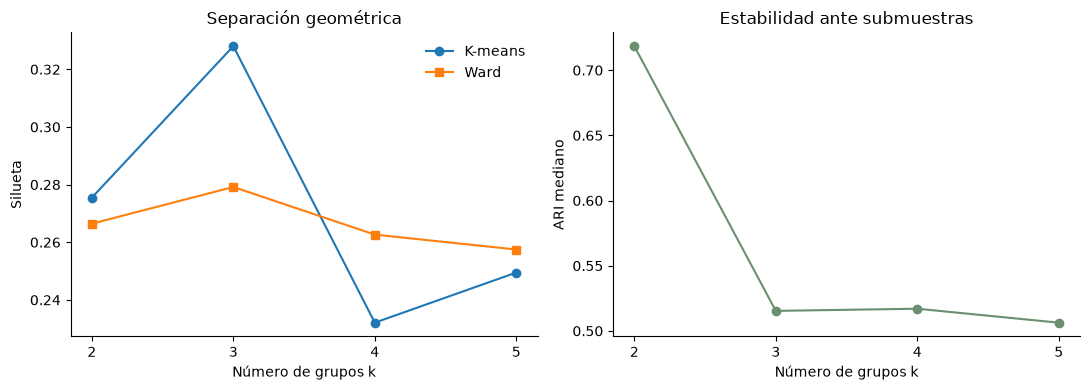

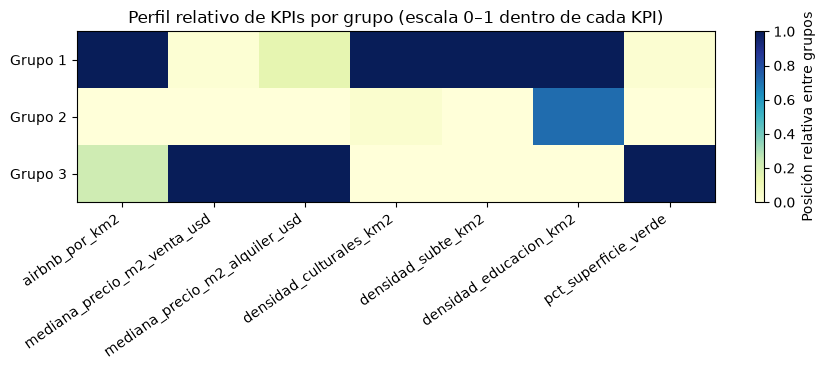

In [5]:
from src.pe3_visuals import kpi_cards
fila_k = validacion.loc[validacion["k"] == k_candidato].iloc[0]
tam = asignacion["cluster"].value_counts().sort_index()
kpi_cards([
 ("k candidato", str(k_candidato), "selección geométrica provisional"),
 ("Silueta K-means", f"{fila_k['silueta_kmeans']:.3f}", "separación en el espacio PCA"),
 ("ARI estabilidad", f"{fila_k['ari_mediana_submuestras']:.3f}", "mediana entre submuestras"),
 ("Grupo menor", f"{int(tam.min())} barrios", "revisar si es demasiado pequeño"),
], title="Segmentación barrial · diagnóstico",
note="Silueta y ARI evalúan propiedades distintas; la utilidad pública requiere interpretación.")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(validacion["k"], validacion["silueta_kmeans"], marker="o", label="K-means")
axes[0].plot(validacion["k"], validacion["silueta_ward"], marker="s", label="Ward")
axes[0].set(title="Separación geométrica", xlabel="Número de grupos k", ylabel="Silueta")
axes[0].legend(frameon=False)
axes[1].plot(validacion["k"], validacion["ari_mediana_submuestras"], marker="o", color="#6b8f71")
axes[1].set(title="Estabilidad ante submuestras", xlabel="Número de grupos k", ylabel="ARI mediano")
for ax in axes:
    for spine in ("top","right"):
        ax.spines[spine].set_visible(False)
    ax.set_xticks(validacion["k"])
plt.tight_layout(); plt.show()
heat = resumen.drop(columns=["barrios"], errors="ignore").astype(float)
den = heat.max() - heat.min()
heat01 = (heat - heat.min()) / den.replace(0, np.nan)
fig, ax = plt.subplots(figsize=(9, 3.8))
im=ax.imshow(heat01.to_numpy(), cmap="YlGnBu", vmin=0, vmax=1, aspect="auto")
ax.set_yticks(np.arange(len(heat01))); ax.set_yticklabels(["Grupo "+str(i) for i in heat01.index])
ax.set_xticks(np.arange(len(heat01.columns))); ax.set_xticklabels(heat01.columns, rotation=35, ha="right")
ax.set_title("Perfil relativo de KPIs por grupo (escala 0–1 dentro de cada KPI)")
fig.colorbar(im,ax=ax,label="Posición relativa entre grupos")
plt.tight_layout(); plt.show()

**Interpretación provisional.** La lectura cuantitativa se genera desde las tablas ejecutadas al cierre de este notebook. El notebook 16 contrasta estabilidad, supuestos y sensibilidad. Los resultados describen oferta publicada y asociaciones; la redacción final se acordará al cerrar la entrega.

**Interpretación.** Si un grupo pequeño o inestable concentra la señal, evitar convertirlo en categoría de intervención. Volver a los valores y unidades originales de `resumen`; el mapa de calor solo ayuda a encontrar contrastes.

## Interpretación provisional vinculada con las salidas
Los valores siguientes se recalculan en cada ejecución. La escritura final y el README quedan pendientes de revisión conjunta.

**Advertencia inferencial.** Los contrastes entre clusters sobre variables que participaron en su construcción son descriptivos postselección. Sus p-valores no validan independientemente los clusters. Con grupos de un barrio, la aproximación asintótica de Kruskal–Wallis es especialmente frágil. La comparación fuera de muestra con comunas y las variables suplementarias se evalúan en 16.

In [6]:
from IPython.display import Markdown
v=validacion.loc[validacion.k.eq(k_candidato)].iloc[0]
sizes=asignacion.cluster.value_counts().sort_index()
display(Markdown(f"La selección geométrica provisional propone **k={k_candidato}**, silueta **{v.silueta_kmeans:.3f}** "
    f"y ARI mediano **{v.ari_mediana_submuestras:.3f}**. Tamaños: **{sizes.to_dict()}**. "
    'El máximo de silueta entre valores evaluados no demuestra una partición natural ni utilidad pública.'))
for cl,row in resumen.iterrows():
    display(Markdown(f"**Grupo {cl}:** {int(row['barrios'])} barrios; Airbnb/km²={row['airbnb_por_km2']:.2f}; "
                    f"educación/km²={row['densidad_educacion_km2']:.2f}; verde={row['pct_superficie_verde']:.2f}%."))
display(Markdown('Los grupos pequeños se describen como casos particulares. '
                'Las pruebas sobre variables activas son postselección; ver validación LOO, comparación con comunas y exclusión de Puerto Madero en 16.'))

La selección geométrica provisional propone **k=3**, silueta **0.328** y ARI mediano **0.515**. Tamaños: **{1: 10, 2: 37, 3: 1}**. El máximo de silueta entre valores evaluados no demuestra una partición natural ni utilidad pública.

**Grupo 1:** 10 barrios; Airbnb/km²=145.63; educación/km²=9.80; verde=2.40%.

**Grupo 2:** 37 barrios; Airbnb/km²=5.12; educación/km²=7.09; verde=1.11%.

**Grupo 3:** 1 barrios; Airbnb/km²=36.88; educación/km²=0.40; verde=52.41%.

Los grupos pequeños se describen como casos particulares. Las pruebas sobre variables activas son postselección; ver validación LOO, comparación con comunas y exclusión de Puerto Madero en 16.